# Data map: what we hold and how it connects

**Internal working notebook.** Directed graphs of the project's data, drawn by
`tools/data_map.py` from the repo itself. Nothing here is hand-drawn, so re-running
picks up a new `src/` step, a new member or a changed exclusion:
- **Pipeline**: publisher → `src/` step → file, read from each step's argparse defaults.
- **Region** (Edmonton, Calgary): region → core/ring → member → input dataset → output
  series, with year coverage read from `data/processed/`.

How to read them:
- Node colours: blue = publisher or region; tan = `src/` step or input dataset;
  green = committed file or built series; **amber = built locally only (gitignored)**,
  or a file not built on this machine; grey dashed = raw downloads (never committed).
- A dataset's node gives its common year span. A member's edge is labelled only where
  the member differs from that span (a correction, a gap).
- **Orange dashed** = member left out of that series: police where the province polices
  (RCMP) and unexplained zero years, or a classification-unstable series not built
  (decision 2026-10-10).
- **Blue dotted** = annexation between two members (loser → gainer), from
  `data/annexations.csv`.

Rebuild: `.venv/bin/jupytext --sync notebooks/02_data_map.py` then
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/02_data_map.ipynb`.
The same graphs as a web page: `.venv/bin/python tools/data_map.py --html <path>`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "tools"))
import data_map as dm  # noqa: E402

## Pipeline

Read left to right: publishers, the fetch steps, raw downloads, parse and build steps,
processed tables. `equalized_long.csv` and `member_assessment.csv` are gitignored, so a
fresh clone has to run `fetch_equalized` → `parse_equalized` → `build_share_series`
to get them; everything else under `processed/` is committed.

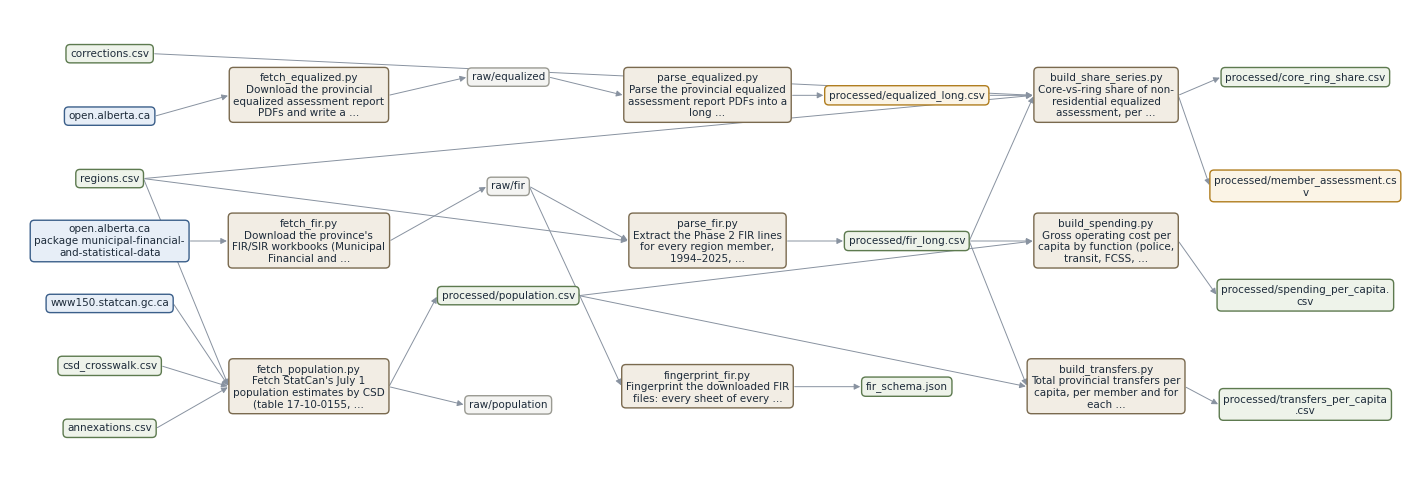

In [2]:
dm.draw(dm.pipeline_graph())
plt.show()

## Edmonton region (EMRB 2025 membership, applied to every year)

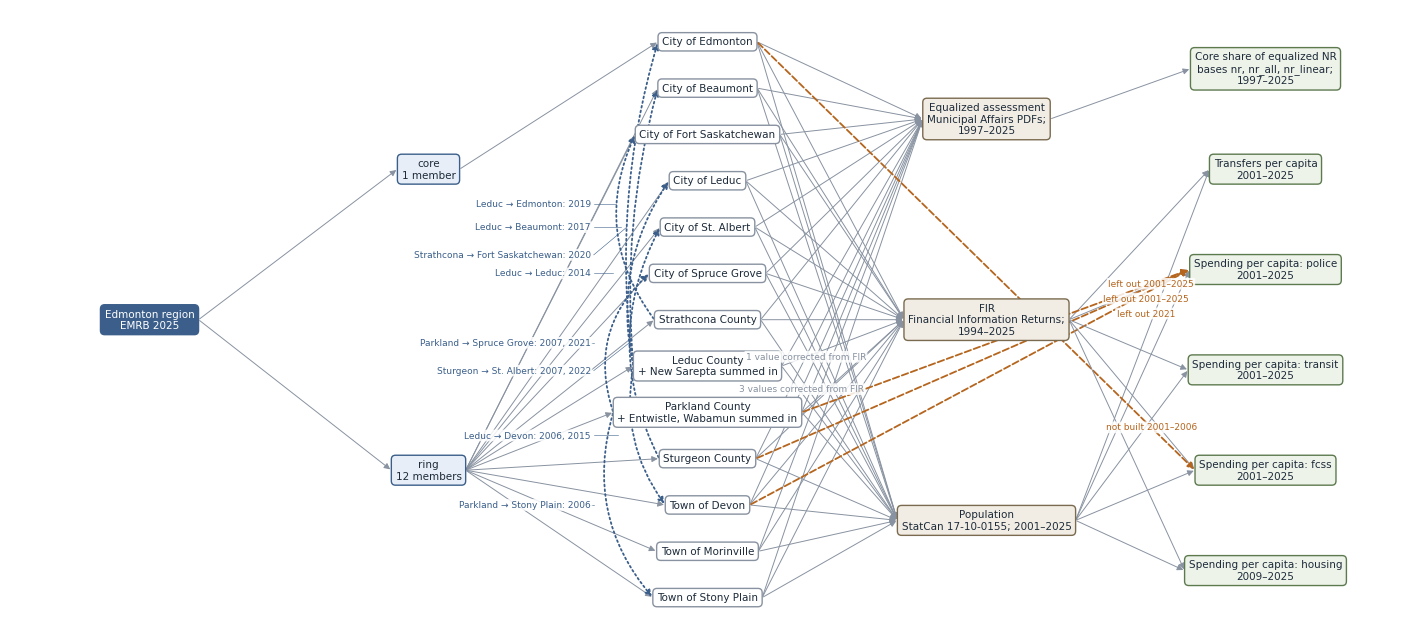

In [3]:
dm.draw(dm.region_graph("edmonton"))
plt.show()

Where each Edmonton member differs from the dataset spans above. "all" = the dataset's
full span; a blank series column = the member is in every year of that series.

In [4]:
pd.DataFrame(dm.coverage_table("edmonton")).fillna("").set_index("member")

,Equalized assessment,FIR,Population,Spending per capita: fcss,Spending per capita: police
member,,,,,
City of Edmonton,all,all,all,not built 2001–2006,
City of Beaumont,all,all,all,,
City of Fort Saskatchewan,all,all,all,,
City of Leduc,all,all,all,,
City of St. Albert,all,all,all,,
City of Spruce Grove,all,all,all,,
Strathcona County,all,all,all,,
Leduc County,all,all,all,,
Parkland County,all,all,all,,left out 2001–2025


## Calgary region (CMRB 2025 membership, applied to every year)

Calgary's core-vs-ring spending comparison is police and transit only: its FCSS and
housing lines aren't built in any year (decision 2026-10-10).

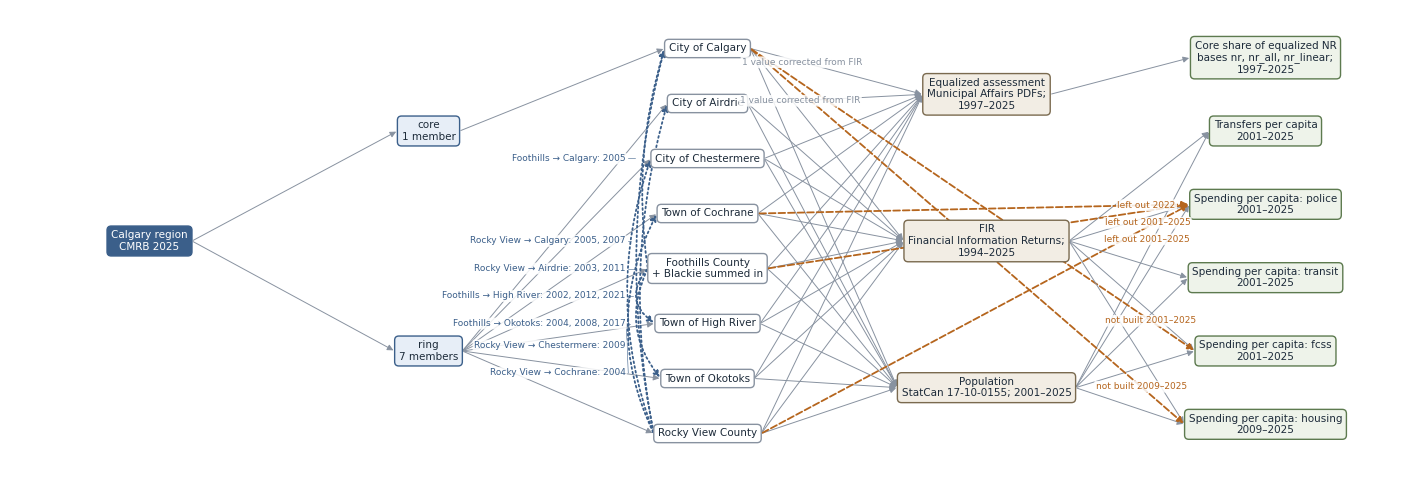

In [5]:
dm.draw(dm.region_graph("calgary"))
plt.show()

In [6]:
pd.DataFrame(dm.coverage_table("calgary")).fillna("").set_index("member")

,Equalized assessment,FIR,Population,Spending per capita: fcss,Spending per capita: housing,Spending per capita: police
member,,,,,,
City of Calgary,1 value corrected from FIR,all,all,not built 2001–2025,not built 2009–2025,
City of Airdrie,1 value corrected from FIR,all,all,,,
City of Chestermere,all,all,all,,,
Town of Cochrane,all,all,all,,,left out 2022
Foothills County,all,all,all,,,left out 2001–2025
Town of High River,all,all,all,,,
Town of Okotoks,all,all,all,,,
Rocky View County,all,all,all,,,left out 2001–2025
